## Semantic Query Caching Simulation — DBpedia (`tab:caching`)

Implements the protocol in `notebooks/caching/README.md` exactly as committed
to in the paper (§Downstream Application):

- **Stream:** held-out SQuARE **test split** anchors, seeded shuffle.
- **Cache:** FIFO over the **K most recent** executed queries (embedding +
  result set). Hit when max cosine ≥ θ → return the cached result, do not
  insert. Miss → "execute" (oracle lookup) and insert.
- **Grid:** K ∈ {32, 64, 128, 256} × θ ∈ {0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95},
  swept over **5 shuffle seeds** and reported as **mean ± std**. The θ
  sweep traces each model's hit-rate / result-quality **Pareto** curve.
- **Models:** SparqlCE, TF-IDF, BM25, E5-base-v2, Qwen2.5-Coder-0.5B
  (generative code LLM, last-token), CodeBERT, GraphCodeBERT, SPBERT,
  SBERT/MiniLM, SBERT/MPNet, and the fine-tuned E5-base-v2 baseline.
- **Metrics:** hit rate; result quality = mean answer-set Jaccard between the
  returned (cached) result and the true result, over hits.

Requires the SparqlCE checkpoint `sparqlce/models/final_model_mrr_0.4487.pt`
(not in git — see the main README). Everything
else is in `datasets/`. Outputs `results/caching/caching_dbpedia.json` and
ready-to-paste LaTeX rows for `tab:caching`.


In [1]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is not available.")

if torch.cuda.device_count() < 2:
    raise RuntimeError(f"GPU 1 is unavailable. Found {torch.cuda.device_count()} GPU(s).")

torch.cuda.set_device(1)
DEVICE = "cuda:1"

print(f"Using device: {DEVICE}")
print(f"GPU: {torch.cuda.get_device_name(1)}")
print(f"Allocated memory: {torch.cuda.memory_allocated(1) / 1024**2:.1f} MiB")

Using device: cuda:1
GPU: NVIDIA RTX A5000
Allocated memory: 0.0 MiB


In [2]:
import gc
import os

# Must be set before the first CUDA call (i.e. before `import torch` touches
# the GPU), so cuBLAS allocates a deterministic workspace.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import sys
import json
import random
from pathlib import Path
from collections import deque

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

# ---- Project root (works from notebooks/caching/ or anywhere in the repo) ----
_PROJECT_ROOT = Path.cwd()
while not (_PROJECT_ROOT / "datasets").exists():
    assert _PROJECT_ROOT != _PROJECT_ROOT.parent, "could not locate repo root"
    _PROJECT_ROOT = _PROJECT_ROOT.parent

if str(_PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(_PROJECT_ROOT))


# ---- Config ----
TRIPLETS_PATH = (
    _PROJECT_ROOT
    / "datasets"
    / "dbpedia-triplets-dataset.json"
)

SPLITS_PATH = (
    _PROJECT_ROOT
    / "datasets"
    / "splits_dbpedia.json"
)

RESULTS_PATH = (
    _PROJECT_ROOT
    / "datasets"
    / "result_sets_dbpedia.json"
)

SPARQLCE_CKPT = (
    _PROJECT_ROOT
    / "checkpoints"
    / "sparqlce_dbpedia"
    / "best_model.pt"
)

OUT_DIR = (
    _PROJECT_ROOT
    / "results"
    / "caching"
)


# Stream shuffle seeds. Each seed is an independent arrival ORDER over the
# same held-out queries. Embeddings are computed once on the base (unshuffled)
# stream and permuted per seed (see the simulation driver), so seeds isolate
# the effect of arrival order. Results are reported as mean +/- std over seeds.
SEEDS = [42, 1, 2, 3, 4]
SEED = SEEDS[0]  # also seeds torch/numpy determinism below

K_GRID = [
    32,
    64,
    128,
    256,
]

# Full theta sweep -> hit-rate / result-quality Pareto curve per model.
THETA_GRID = [
    0.5,
    0.6,
    0.7,
    0.75,
    0.8,
    0.85,
    0.9,
    0.95,
]

# (K, theta) operating point reported in the main LaTeX table.
HEADLINE = (128, 0.8)


DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


# ---------------------------------------------------------------------------
# Determinism.
#
# SEED only fixes the stream shuffle order and RNG-based initialization -- it
# does not make CUDA kernels bit-reproducible run to run. Repeated executions
# of this notebook showed SparqlCE (GATv2 scatter/gather message passing) and
# both Qwen3 paths (dense attention kernels) drifting between runs, while
# every sparse/SentenceTransformer baseline (TF-IDF, BM25, E5, MiniLM, MPNet)
# stayed bit-identical across reruns. Force determinism everywhere torch
# supports it; an op with no deterministic GPU kernel will raise here instead
# of silently drifting into a different cache trajectory. See the SparqlCE
# encode cell below for a CPU fallback if the GNN's aggregation still raises.
# ---------------------------------------------------------------------------
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

print(
    f"project root: {_PROJECT_ROOT}\n"
    f"device: {DEVICE}"
)

/upb/users/g/ganeshk/profiles/unix/cs/.conda/envs/sparql/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


project root: /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings
device: cuda


In [3]:
def normalize_query(q: str) -> str:
    """
    Normalize query formatting for exact oracle lookup only.

    The original query string is still used for embedding.
    """
    return " ".join(q.split())


def freeze_json(value):
    """
    Convert a JSON-compatible value into a recursively hashable form.

    This allows result rows represented as lists or dictionaries to be
    stored safely in a frozenset for answer-set Jaccard computation.
    """
    if isinstance(value, dict):
        return tuple(
            sorted(
                (
                    key,
                    freeze_json(item),
                )
                for key, item in value.items()
            )
        )

    if isinstance(value, list):
        return tuple(
            freeze_json(item)
            for item in value
        )

    return value


with open(
    TRIPLETS_PATH,
    encoding="utf-8",
) as f:
    triplets = json.load(f)


with open(
    SPLITS_PATH,
    encoding="utf-8",
) as f:
    splits = json.load(f)


with open(
    RESULTS_PATH,
    encoding="utf-8",
) as f:
    raw_result_sets = json.load(f)


# ---------------------------------------------------------------------------
# Build oracle lookup.
#
# Query keys are normalized only for exact oracle lookup.
# Result rows are converted into hashable canonical Python structures.
#
# A normalization collision with different result sets is treated as an error
# rather than silently overwriting one oracle entry with another.
# ---------------------------------------------------------------------------
result_sets = {}

for raw_query, rows in raw_result_sets.items():

    if not rows:
        continue

    query_key = normalize_query(raw_query)

    answer_set = frozenset(
        freeze_json(row)
        for row in rows
    )

    if (
        query_key in result_sets
        and result_sets[query_key] != answer_set
    ):
        raise ValueError(
            "Conflicting oracle result sets after query normalization:\n"
            f"{query_key}"
        )

    result_sets[query_key] = answer_set


# ---------------------------------------------------------------------------
# Build train/test anchor collections from the committed split.
# ---------------------------------------------------------------------------
test_anchors = [
    triplets[i]["anchor_query"]
    for i in splits["test_idx"]
]

train_anchors = [
    triplets[i]["anchor_query"]
    for i in splits["train_idx"]
]


# ---------------------------------------------------------------------------
# Keep ORIGINAL query strings in the stream for embedding.
#
# Normalized query strings are used only for oracle lookup.
# ---------------------------------------------------------------------------
stream = [
    q
    for q in test_anchors
    if normalize_query(q) in result_sets
]

dropped = (
    len(test_anchors)
    - len(stream)
)


# ---------------------------------------------------------------------------
# Keep the stream in its deterministic (unshuffled) base order here.
#
# Per-seed shuffling happens in the simulation driver (Section 3): embeddings
# are computed once on THIS order, then the stream and its embedding matrix are
# permuted together for each seed. This preserves "embed once" while letting
# arrival order vary across seeds.
#
# This deliberately does NOT deduplicate repeated anchors: if the same query
# occurs multiple times in the held-out workload, those occurrences remain
# separate stream events.
# ---------------------------------------------------------------------------


# ---------------------------------------------------------------------------
# Diagnostics only. These values do not change the experiment.
# ---------------------------------------------------------------------------
stream_unique_queries = len(
    {
        normalize_query(q)
        for q in stream
    }
)

duplicate_stream_events = (
    len(stream)
    - stream_unique_queries
)


print(
    f"test anchors: {len(test_anchors)} | "
    f"in stream: {len(stream)} | "
    f"dropped (missing/empty oracle result): {dropped}"
)

print(
    f"unique normalized queries in stream: "
    f"{stream_unique_queries} | "
    f"repeated stream events: "
    f"{duplicate_stream_events}"
)


def jaccard(
    a: frozenset,
    b: frozenset,
) -> float:
    """
    Answer-set Jaccard similarity.
    """
    union = len(a | b)

    # Two empty answer sets are identical: a query that correctly returns no
    # bindings, served from a cached query that also returns no bindings, is an
    # EXACT hit (Jaccard 1.0), not a catastrophic miss. Empty oracle results
    # are filtered upstream, so this only guards robustness -- but the
    # convention must be correct.
    return (
        len(a & b) / union
        if union
        else 1.0
    )

test anchors: 472 | in stream: 396 | dropped (missing/empty oracle result): 76
unique normalized queries in stream: 396 | repeated stream events: 0


In [4]:
# ============================================================================
# 2. Embed the stream once per model
#
# Every representation is L2-normalised so that the cache lookup can continue
# to use a common cosine-similarity threshold grid.
# ============================================================================

from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import normalize
from sentence_transformers import SentenceTransformer

stream_embeddings = {}


def clear_model(model):
    """Release a transformer model and clear accelerator memory."""
    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ---------------------------------------------------------------------------
# SparqlCE — trained checkpoint
#
# GATv2's scatter/gather message passing is the one op in this notebook that
# may lack a deterministic CUDA kernel under torch.use_deterministic_algorithms.
# Try the default device first; if that op raises, fall back to CPU (cheap --
# only ~400 short queries) rather than silently accept a nondeterministic run.
# ---------------------------------------------------------------------------
from sparqlce.embedder import SPARQLEmbedder
from sparqlce.config import Config as _SparqlCEConfig


def _encode_with_sparqlce(stream, batch_size=32):
    original_device = _SparqlCEConfig.DEVICE
    try:
        embedder = SPARQLEmbedder(str(SPARQLCE_CKPT))
        embs = [
            embedder.encode(stream[i : i + batch_size])
            for i in tqdm(
                range(0, len(stream), batch_size), desc="SparqlCE"
            )
        ]
    except RuntimeError as exc:
        if "deterministic" not in str(exc).lower():
            raise
        print(
            f"SparqlCE GPU encode is non-deterministic ({exc});"
            " falling back to CPU."
        )
        _SparqlCEConfig.DEVICE = torch.device("cpu")
        embedder = SPARQLEmbedder(str(SPARQLCE_CKPT))
        embs = [
            embedder.encode(stream[i : i + batch_size])
            for i in tqdm(
                range(0, len(stream), batch_size), desc="SparqlCE (CPU)"
            )
        ]
    finally:
        _SparqlCEConfig.DEVICE = original_device
    return embedder, embs


sparqlce, embs = _encode_with_sparqlce(stream)

stream_embeddings["SparqlCE"] = normalize(
    np.vstack(embs),
    norm="l2",
    axis=1,
).astype(
    np.float32,
    copy=False,
)

del sparqlce
del embs
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ---------------------------------------------------------------------------
# TF-IDF
#
# Vocabulary and IDF statistics are fit on TRAIN anchors only.
# ---------------------------------------------------------------------------
tfidf = TfidfVectorizer(
    norm="l2",
).fit(
    train_anchors
)

stream_embeddings["TF-IDF"] = (
    tfidf
    .transform(stream)
    .toarray()
    .astype(np.float32, copy=False)
)


# ---------------------------------------------------------------------------
# BM25
#
# The cache simulator requires a bounded cosine similarity because theta is
# shared across all baselines. We therefore build Okapi-BM25 term-weight
# vectors using TRAIN-anchor corpus statistics, then L2-normalise each vector.
# Cache lookup remains a cosine comparison between query representations.
# ---------------------------------------------------------------------------
class BM25Vectorizer:
    """Okapi-BM25 term weighting with optional row normalisation."""

    def __init__(
        self,
        *,
        k1=1.5,
        b=0.75,
        norm="l2",
        **count_vectorizer_kwargs,
    ):
        self.k1 = float(k1)
        self.b = float(b)
        self.norm = norm
        self.vectorizer = CountVectorizer(
            **count_vectorizer_kwargs
        )

    def fit(self, documents):
        counts = (
            self.vectorizer
            .fit_transform(documents)
            .tocsr()
            .astype(np.float32)
        )

        n_documents = counts.shape[0]

        if n_documents == 0:
            raise ValueError(
                "BM25Vectorizer cannot be fit on an empty corpus."
            )

        document_frequency = np.asarray(
            (counts > 0).sum(axis=0)
        ).ravel()

        # Robertson/Sparck Jones IDF with the common +1 stabilisation.
        self.idf_ = np.log(
            1.0
            + (
                n_documents
                - document_frequency
                + 0.5
            )
            / (
                document_frequency
                + 0.5
            )
        ).astype(np.float32)

        document_lengths = np.asarray(
            counts.sum(axis=1)
        ).ravel()

        self.avg_document_length_ = float(
            document_lengths.mean()
        )

        if self.avg_document_length_ <= 0:
            raise ValueError(
                "BM25Vectorizer received only empty documents."
            )

        return self

    def transform(self, documents):
        counts = (
            self.vectorizer
            .transform(documents)
            .tocoo()
            .astype(np.float32)
        )

        document_lengths = np.asarray(
            counts.tocsr().sum(axis=1)
        ).ravel()

        length_factor = (
            1.0
            - self.b
            + self.b
            * (
                document_lengths
                / self.avg_document_length_
            )
        )

        denominator = (
            counts.data
            + self.k1
            * length_factor[counts.row]
        )

        weighted_data = (
            self.idf_[counts.col]
            * counts.data
            * (self.k1 + 1.0)
            / denominator
        )

        weighted = sparse.csr_matrix(
            (
                weighted_data,
                (
                    counts.row,
                    counts.col,
                ),
            ),
            shape=counts.shape,
            dtype=np.float32,
        )

        if self.norm is not None:
            weighted = normalize(
                weighted,
                norm=self.norm,
                axis=1,
                copy=False,
            )

        return weighted

    def fit_transform(self, documents):
        return (
            self
            .fit(documents)
            .transform(documents)
        )


bm25 = BM25Vectorizer(
    k1=1.5,
    b=0.75,
    norm="l2",
).fit(
    train_anchors
)

stream_embeddings["BM25"] = (
    bm25
    .transform(stream)
    .toarray()
    .astype(np.float32, copy=False)
)


# ---------------------------------------------------------------------------
# Dense text-embedding baselines
# ---------------------------------------------------------------------------
model_specs = [
    {
        "name": "E5-base-v2",
        "model_id": "intfloat/e5-base-v2",
        "texts": [
            f"query: {q}"
            for q in stream
        ],
        "batch_size": 32,
    },
    {
        "name": "SBERT/MiniLM",
        "model_id": "sentence-transformers/all-MiniLM-L6-v2",
        "texts": stream,
        "batch_size": 64,
    },
    {
        "name": "SBERT/MPNet",
        "model_id": "sentence-transformers/all-mpnet-base-v2",
        "texts": stream,
        "batch_size": 32,
    },
    {
        "name": "CodeBERT",
        "model_id": "microsoft/codebert-base",
        "texts": stream,
        "batch_size": 64,
    },
    {
        "name": "GraphCodeBERT",
        "model_id": "microsoft/graphcodebert-base",
        "texts": stream,
        "batch_size": 64,
    },
    {
        "name": "SPBERT",
        "model_id": "razent/spbert-mlm-wso-base",
        "texts": stream,
        "batch_size": 64,
    },
]


for spec in model_specs:
    model = SentenceTransformer(
        spec["model_id"],
        device=DEVICE,
    )

    encoded = model.encode(
        spec["texts"],
        convert_to_numpy=True,
        normalize_embeddings=False,
        show_progress_bar=True,
        batch_size=spec["batch_size"],
    ).astype(
        np.float32,
        copy=False,
    )

    # Explicit post-normalisation avoids small model/dtype-dependent norm drift
    # (observed for Qwen3-Embedding-0.6B despite normalize_embeddings=True).
    stream_embeddings[
        spec["name"]
    ] = normalize(
        encoded,
        norm="l2",
        axis=1,
        copy=False,
    ).astype(
        np.float32,
        copy=False,
    )

    del encoded
    clear_model(model)


# ============================================================================
# Qwen2.5-Coder-0.5B — generative code LLM used as an embedder (last-token
# pooling), replacing the dense Qwen3-Embedding-0.6B. Off-label use of a
# generative model; 0.5B roughly scale-matches the 0.6B it replaces.
# ============================================================================
from transformers import AutoModel, AutoTokenizer
import torch.nn.functional as F

CODER_MODEL = "Qwen/Qwen2.5-Coder-0.5B"
CODER_NAME = "Qwen2.5-Coder-0.5B"

def _last_token_pool(h, am):
    if (am[:, -1].sum() == am.shape[0]):        # left-padded
        return h[:, -1]
    lens = am.sum(dim=1) - 1
    idx = torch.arange(h.shape[0], device=h.device)
    return h[idx, lens]

coder_tok = AutoTokenizer.from_pretrained(CODER_MODEL, padding_side="left")
if coder_tok.pad_token_id is None:
    coder_tok.pad_token = coder_tok.eos_token
coder_model = AutoModel.from_pretrained(CODER_MODEL, torch_dtype=torch.float32).to(DEVICE).eval()

@torch.inference_mode()
def encode_coder(queries, batch_size=8, max_length=512):
    out = []
    for start in tqdm(range(0, len(queries), batch_size), desc=CODER_NAME):
        batch = queries[start:start + batch_size]
        tok = coder_tok(batch, padding=True, truncation=True, max_length=max_length, return_tensors="pt")
        tok = {k: v.to(DEVICE) for k, v in tok.items()}
        h = coder_model(input_ids=tok["input_ids"], attention_mask=tok["attention_mask"]).last_hidden_state
        emb = F.normalize(_last_token_pool(h, tok["attention_mask"]).float(), p=2, dim=1)
        out.append(emb.cpu().numpy())
    return np.vstack(out).astype(np.float32, copy=False)

stream_embeddings[CODER_NAME] = encode_coder(stream)
del coder_model, coder_tok
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ============================================================================
# Fine-tuned E5-base-v2 — SQuARE DBpedia full fine-tune (capacity-matched
# fine-tuned baseline; replaces the fine-tuned Qwen3 baseline). Mean pooling,
# "query: " prefix, matching 04_e5_contrastive_finetune_square.ipynb.
# ============================================================================
FT_E5_PATH = _PROJECT_ROOT / "checkpoints" / "e5_square_dbpedia" / "best_model"
FT_E5_NAME = "E5-base-v2 (fine-tuned)"

if not FT_E5_PATH.exists():
    raise FileNotFoundError(
        f"Fine-tuned E5 model not found: {FT_E5_PATH} — run "
        "notebooks/finetuning/04_e5_contrastive_finetune_square.ipynb first."
    )

ft_e5_tok = AutoTokenizer.from_pretrained(str(FT_E5_PATH))
ft_e5_model = AutoModel.from_pretrained(str(FT_E5_PATH), torch_dtype=torch.float32).to(DEVICE).eval()

def _mean_pool(h, am):
    m = am.unsqueeze(-1).float()
    return (h * m).sum(1) / m.sum(1).clamp(min=1e-9)

@torch.inference_mode()
def encode_ft_e5(queries, batch_size=32, max_length=512):
    out = []
    for start in tqdm(range(0, len(queries), batch_size), desc=FT_E5_NAME):
        batch = [f"query: {q}" for q in queries[start:start + batch_size]]
        tok = ft_e5_tok(batch, padding=True, truncation=True, max_length=max_length, return_tensors="pt")
        tok = {k: v.to(DEVICE) for k, v in tok.items()}
        h = ft_e5_model(input_ids=tok["input_ids"], attention_mask=tok["attention_mask"]).last_hidden_state
        emb = F.normalize(_mean_pool(h, tok["attention_mask"]).float(), p=2, dim=1)
        out.append(emb.cpu().numpy())
    return np.vstack(out).astype(np.float32, copy=False)

stream_embeddings[FT_E5_NAME] = encode_ft_e5(stream)
del ft_e5_model, ft_e5_tok
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ---------------------------------------------------------------------------
# Sanity checks
# ---------------------------------------------------------------------------
for name, E in stream_embeddings.items():
    if E.shape[0] != len(stream):
        raise ValueError(
            f"{name}: expected {len(stream)} rows, got {E.shape[0]}"
        )

    row_norms = np.linalg.norm(
        E,
        axis=1,
    )

    nonzero_rows = row_norms > 0

    if np.any(nonzero_rows) and not np.allclose(
        row_norms[nonzero_rows],
        1.0,
        atol=1e-5,
    ):
        raise ValueError(
            f"{name}: non-zero rows are not L2-normalised."
        )

    print(
        f"{name:>24}: {E.shape}"
    )

Loading model from /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/checkpoints/sparqlce_dbpedia/best_model.pt...


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 40912.95it/s]
[transformers] RobertaModel LOAD REPORT from: microsoft/graphcodebert-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.decoder.weight    | UNEXPECTED | 
lm_head.decoder.bias      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Loading weights: 100%|██████████| 197/197 [00:00<00:00, 42215.19it/s]
[transformers] BertModel LOAD REPORT from: razent/spbert-mlm-wso-base
Key  

                SparqlCE: (396, 128)
                  TF-IDF: (396, 3670)
                    BM25: (396, 3670)
              E5-base-v2: (396, 768)
            SBERT/MiniLM: (396, 384)
             SBERT/MPNet: (396, 768)
                CodeBERT: (396, 768)
           GraphCodeBERT: (396, 768)
                  SPBERT: (396, 768)
      Qwen2.5-Coder-0.5B: (396, 896)
 E5-base-v2 (fine-tuned): (396, 768)


In [5]:
# ============================================================================
# 3. Cache simulation
#
# Protocol:
#   - FIFO over the K most recent EXECUTED queries.
#   - Hit when max cosine similarity >= theta.
#   - On a hit: return the cached result and do not modify the cache.
#   - On a miss: use the oracle result and insert the query/result pair.
#
# Driven over SEEDS x K_GRID x THETA_GRID. Embeddings are computed once on the
# base stream; each seed permutes the arrival order (stream + embeddings
# together). Per-(K, theta) cells aggregate to mean +/- std across seeds.
# ============================================================================

def simulate(stream, E, result_sets, K, theta):
    """
    Run one pass over the query stream. E[i] is the L2-normalised embedding of
    stream[i]. Returns hit rate plus answer-set quality / reliability metrics.
    """
    if len(stream) == 0:
        raise ValueError("Cannot simulate an empty query stream.")
    if len(E) != len(stream):
        raise ValueError(
            "Embedding matrix length does not match stream length: "
            f"{len(E)} != {len(stream)}"
        )
    if K <= 0:
        raise ValueError(f"K must be positive, got {K}.")

    # maxlen=K gives FIFO eviction automatically.
    cache = deque(maxlen=K)
    hits = 0
    qualities = []

    for i, q in enumerate(stream):
        R_true = result_sets[normalize_query(q)]

        if cache:
            cached_embeddings = np.stack([entry[0] for entry in cache])
            sims = cached_embeddings @ E[i]
            best = int(np.argmax(sims))

            # Hit: serve nearest cached result; do not execute, insert, or
            # refresh cache position.
            if float(sims[best]) >= theta:
                R_cached = cache[best][1]
                hits += 1
                qualities.append(jaccard(R_cached, R_true))
                continue

        # Miss: "execute" through the offline oracle and insert into the cache.
        cache.append((E[i], R_true))

    n = len(stream)
    q = np.asarray(qualities, dtype=float)
    return {
        "hit_rate": hits / n,
        # mean Jaccard over hits only (None if no hits)
        "result_quality": float(q.mean()) if hits else None,
        # served quality per stream query (0 for a miss); always defined
        "utility": float(q.sum() / n),
        # fraction of hits that were "reliable" (Jaccard >= 0.8)
        "reliable_hit_precision": float((q >= 0.8).mean()) if hits else None,
        # fraction of hits that were exact (Jaccard == 1.0)
        "exact_hit_precision": float((q == 1.0).mean()) if hits else None,
        "n_hits": hits,
        "n_misses": n - hits,
        "n_queries": n,
    }


def _mean_std(values):
    a = np.asarray([v for v in values if v is not None], dtype=float)
    if a.size == 0:
        return None, None
    return float(a.mean()), (float(a.std(ddof=1)) if a.size > 1 else 0.0)


def aggregate(runs, seeds):
    """Aggregate per-seed simulate() outputs into mean +/- std."""
    hr_m, hr_s = _mean_std([r["hit_rate"] for r in runs])
    ut_m, ut_s = _mean_std([r["utility"] for r in runs])
    rq_m, rq_s = _mean_std([r["result_quality"] for r in runs])
    rp_m, rp_s = _mean_std([r["reliable_hit_precision"] for r in runs])
    ep_m, ep_s = _mean_std([r["exact_hit_precision"] for r in runs])
    return {
        "hit_rate_mean": hr_m, "hit_rate_std": hr_s,
        "result_quality_mean": rq_m, "result_quality_std": rq_s,
        "utility_mean": ut_m, "utility_std": ut_s,
        "reliable_hit_precision_mean": rp_m, "reliable_hit_precision_std": rp_s,
        "exact_hit_precision_mean": ep_m, "exact_hit_precision_std": ep_s,
        "n_seeds": len(seeds), "seeds": list(seeds),
        "per_seed": {int(s): r for s, r in zip(seeds, runs)},
    }


# One permutation per seed, shared across all models and grid cells so that
# every configuration sees the identical arrival order for a given seed.
_perms = {}
for _s in SEEDS:
    _idx = list(range(len(stream)))
    random.Random(_s).shuffle(_idx)
    _perms[_s] = np.asarray(_idx)


all_results = {}

for name, E in stream_embeddings.items():
    all_results[name] = {}

    # Pre-permute the stream/embeddings once per seed for this model.
    seed_views = {
        s: ([stream[j] for j in perm], E[perm])
        for s, perm in _perms.items()
    }

    for K in K_GRID:
        for theta in THETA_GRID:
            runs = [
                simulate(seed_views[s][0], seed_views[s][1], result_sets, K, theta)
                for s in SEEDS
            ]
            all_results[name][f"K={K},theta={theta}"] = aggregate(runs, SEEDS)

    print(f"done: {name}")


done: SparqlCE
done: TF-IDF
done: BM25
done: E5-base-v2
done: SBERT/MiniLM
done: SBERT/MPNet
done: CodeBERT
done: GraphCodeBERT
done: SPBERT
done: Qwen2.5-Coder-0.5B
done: E5-base-v2 (fine-tuned)


In [6]:
# ============================================================================
# 4. Save the full grid + display
# ============================================================================
OUT_DIR.mkdir(parents=True, exist_ok=True)
payload = {
    "kg": "dbpedia",
    "seeds": SEEDS,
    "stream_length": len(stream),
    "dropped": dropped,
    "grid": {"K": K_GRID, "theta": THETA_GRID},
    "headline": {"K": HEADLINE[0], "theta": HEADLINE[1]},
    "results": all_results,
}
out_json = OUT_DIR / "caching_dbpedia.json"
with open(out_json, "w") as f:
    json.dump(payload, f, indent=2)
print(f"saved {out_json}\n")

# Tidy long-format tables: one row per (model, K, theta) with mean/std, plus a
# per-seed CSV for Pareto plotting and paired significance testing.
rows, seed_rows = [], []
for name, grid in all_results.items():
    for cfg, r in grid.items():
        K, theta = cfg.replace("K=", "").split(",theta=")
        K, theta = int(K), float(theta)
        rows.append({
            "model": name, "K": K, "theta": theta,
            "hit_rate_mean": r["hit_rate_mean"], "hit_rate_std": r["hit_rate_std"],
            "result_quality_mean": r["result_quality_mean"],
            "result_quality_std": r["result_quality_std"],
            "utility_mean": r["utility_mean"], "utility_std": r["utility_std"],
            "reliable_hit_precision_mean": r["reliable_hit_precision_mean"],
            "exact_hit_precision_mean": r["exact_hit_precision_mean"],
        })
        for s, pr in r["per_seed"].items():
            seed_rows.append({
                "model": name, "K": K, "theta": theta, "seed": s,
                "hit_rate": pr["hit_rate"], "result_quality": pr["result_quality"],
                "utility": pr["utility"],
            })

df = pd.DataFrame(rows)
seed_df = pd.DataFrame(seed_rows)
df.to_csv(OUT_DIR / "caching_dbpedia_summary.csv", index=False)
seed_df.to_csv(OUT_DIR / "caching_dbpedia_per_seed.csv", index=False)
print(f"saved summary + per-seed CSVs to {OUT_DIR}\n")


def _fmt(m, s):
    if m is None:
        return "--"
    return f"{m:.3f}±{s:.3f}" if s is not None else f"{m:.3f}"


hk = f"K={HEADLINE[0]},theta={HEADLINE[1]}"
print(
    f"Headline {HEADLINE} — hit rate / result quality "
    f"(mean±std over {len(SEEDS)} seeds):"
)
for name, grid in all_results.items():
    r = grid[hk]
    print(
        f"  {name:>24}: hit={_fmt(r['hit_rate_mean'], r['hit_rate_std'])}  "
        f"quality={_fmt(r['result_quality_mean'], r['result_quality_std'])}"
    )

print("\nHit rate (mean) grid:")
print(df.pivot_table(index="model", columns=["K", "theta"], values="hit_rate_mean").round(3))
print("\nResult quality (mean Jaccard over hits) grid:")
print(df.pivot_table(index="model", columns=["K", "theta"], values="result_quality_mean").round(3))


saved /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/caching/caching_dbpedia.json

saved summary + per-seed CSVs to /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/caching

Headline (128, 0.8) — hit rate / result quality (mean±std over 5 seeds):
                  SparqlCE: hit=0.375±0.007  quality=0.435±0.042
                    TF-IDF: hit=0.762±0.016  quality=0.088±0.021
                      BM25: hit=0.689±0.002  quality=0.090±0.023
                E5-base-v2: hit=0.997±0.001  quality=0.018±0.017
              SBERT/MiniLM: hit=0.954±0.002  quality=0.047±0.021
               SBERT/MPNet: hit=0.943±0.003  quality=0.066±0.021
                  CodeBERT: hit=0.997±0.000  quality=0.018±0.016
             GraphCodeBERT: hit=0.997±0.000  quality=0.018±0.016
                    SPBERT: hit=0.997±0.000  quality=0.018±0.016
        Qwen2.5-Coder-0.5B: hit=0.997±0.000  quality=0.018±0.016
   E5-base-v2 (fine-tuned): hit=0.242±0.004  quality=0.520±0.030

Hit r

saved /upb/users/g/ganeshk/profiles/unix/cs/SPARQL-Embeddings/results/caching/caching_dbpedia_pareto.png


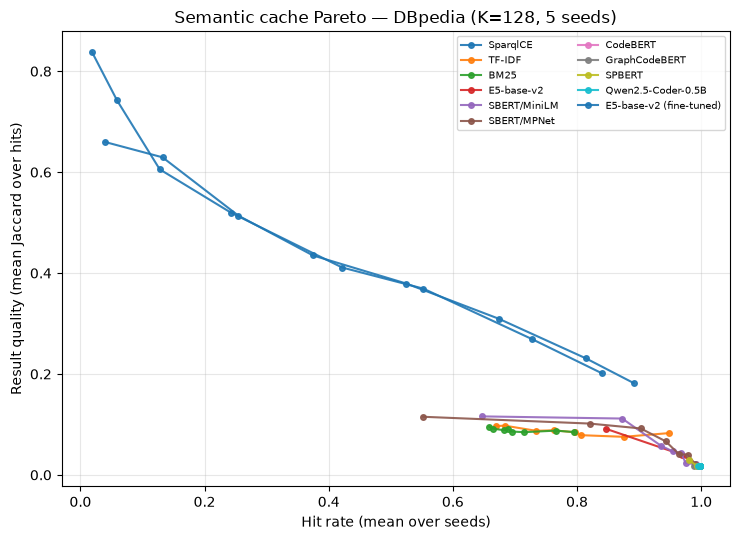

In [7]:
# ============================================================================
# 4b. Pareto curve: hit rate vs. result quality across the theta sweep.
#
# As theta decreases a model accepts more (lower-similarity) hits -> higher hit
# rate, usually lower answer-set quality. Each model therefore traces a curve
# at fixed K; the upper-right envelope is the best hit-rate/quality trade-off.
# ============================================================================
import matplotlib.pyplot as plt

PLOT_K = HEADLINE[0]

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for name, grid in all_results.items():
    pts = []
    for theta in THETA_GRID:
        r = grid[f"K={PLOT_K},theta={theta}"]
        if r["result_quality_mean"] is None:
            continue
        pts.append((r["hit_rate_mean"], r["result_quality_mean"]))
    if not pts:
        continue
    pts.sort()
    hr = [p[0] for p in pts]
    rq = [p[1] for p in pts]
    ax.plot(hr, rq, marker="o", markersize=4, linewidth=1.5, label=name, alpha=0.9)

ax.set_xlabel("Hit rate (mean over seeds)")
ax.set_ylabel("Result quality (mean Jaccard over hits)")
ax.set_title(f"Semantic cache Pareto — DBpedia (K={PLOT_K}, {len(SEEDS)} seeds)")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=7, ncol=2, loc="best")
fig.tight_layout()
fig_path = OUT_DIR / "caching_dbpedia_pareto.png"
fig.savefig(fig_path, dpi=150)
print(f"saved {fig_path}")
plt.show()


In [8]:
# ============================================================================
# 5. LaTeX rows for tab:caching
# ============================================================================

K_h, theta_h = HEADLINE
hk = f"K={K_h},theta={theta_h}"


order = [
    "SparqlCE",
    "TF-IDF",
    "BM25",
    "E5-base-v2",
    "Qwen2.5-Coder-0.5B",
    "CodeBERT",
    "GraphCodeBERT",
    "SPBERT",
    "E5-base-v2 (fine-tuned)",
    "SBERT/MiniLM",
    "SBERT/MPNet",
]


latex_names = {
    "SparqlCE": r"\textsc{SparqlCE}",
    "TF-IDF": "TF-IDF",
    "BM25": "BM25",
    "E5-base-v2": "E5-base-v2",
    "Qwen2.5-Coder-0.5B": "Qwen2.5-Coder-0.5B",
    "CodeBERT": "CodeBERT",
    "GraphCodeBERT": "GraphCodeBERT",
    "SPBERT": "SPBERT",
    "E5-base-v2 (fine-tuned)": "E5-base-v2 (fine-tuned)",
    "SBERT/MiniLM": "SBERT/MiniLM",
    "SBERT/MPNet": "SBERT/MPNet",
}


def latex_pm(mean, std):
    """Format mean +/- std for a LaTeX table; '--' when undefined (no hits)."""
    if mean is None:
        return "--"
    return f"{mean:.3f}$\\pm${std:.3f}" if std is not None else f"{mean:.3f}"


print(
    f"% tab:caching — headline operating point (K={K_h}, theta={theta_h}), "
    f"mean±std over {len(SEEDS)} seeds; full grid in "
    f"results/caching/caching_dbpedia.json"
)


for name in order:
    if name not in all_results:
        continue
    r = all_results[name][hk]
    print(
        f"{latex_names[name]:<24} "
        f"& $({K_h}, {theta_h})$ "
        f"& {latex_pm(r['hit_rate_mean'], r['hit_rate_std'])} "
        f"& {latex_pm(r['result_quality_mean'], r['result_quality_std'])} \\\\"
    )


# ---------------------------------------------------------------------------
# Headline sentence draft
# ---------------------------------------------------------------------------
best = all_results["SparqlCE"][hk]

alts = {
    name: all_results[name][hk]
    for name in order[1:]
    if name in all_results
}

valid_alts = {
    name: result
    for name, result in alts.items()
    if result["result_quality_mean"] is not None
}


print("\n% headline sentence draft:")

if best["result_quality_mean"] is None:
    print(
        f"% At K={K_h}, theta={theta_h}, SparqlCE produces no cache hits, "
        f"so result quality is undefined."
    )

elif not valid_alts:
    print(
        f"% At K={K_h}, theta={theta_h}, SparqlCE serves "
        f"{best['hit_rate_mean']:.0%} of the stream from cache with "
        f"{best['result_quality_mean']:.2f} result quality. No baseline "
        f"produces a cache hit at this operating point."
    )

else:
    best_base = max(
        valid_alts,
        key=lambda name: valid_alts[name]["result_quality_mean"],
    )
    print(
        f"% At K={K_h}, theta={theta_h}, SparqlCE serves "
        f"{best['hit_rate_mean']:.0%} of the stream from cache with "
        f"{best['result_quality_mean']:.2f} result quality, vs. "
        f"{valid_alts[best_base]['result_quality_mean']:.2f} for the best "
        f"baseline ({best_base})."
    )


% tab:caching — headline operating point (K=128, theta=0.8), mean±std over 5 seeds; full grid in results/caching/caching_dbpedia.json
\textsc{SparqlCE}        & $(128, 0.8)$ & 0.375$\pm$0.007 & 0.435$\pm$0.042 \\
TF-IDF                   & $(128, 0.8)$ & 0.762$\pm$0.016 & 0.088$\pm$0.021 \\
BM25                     & $(128, 0.8)$ & 0.689$\pm$0.002 & 0.090$\pm$0.023 \\
E5-base-v2               & $(128, 0.8)$ & 0.997$\pm$0.001 & 0.018$\pm$0.017 \\
Qwen2.5-Coder-0.5B       & $(128, 0.8)$ & 0.997$\pm$0.000 & 0.018$\pm$0.016 \\
CodeBERT                 & $(128, 0.8)$ & 0.997$\pm$0.000 & 0.018$\pm$0.016 \\
GraphCodeBERT            & $(128, 0.8)$ & 0.997$\pm$0.000 & 0.018$\pm$0.016 \\
SPBERT                   & $(128, 0.8)$ & 0.997$\pm$0.000 & 0.018$\pm$0.016 \\
E5-base-v2 (fine-tuned)  & $(128, 0.8)$ & 0.242$\pm$0.004 & 0.520$\pm$0.030 \\
SBERT/MiniLM             & $(128, 0.8)$ & 0.954$\pm$0.002 & 0.047$\pm$0.021 \\
SBERT/MPNet              & $(128, 0.8)$ & 0.943$\pm$0.003 & 0.066$\pm$0.021 

### Notes

- BM25 uses L2-normalized Okapi-BM25 term-weight vectors so that it can be
  evaluated with the same cosine-threshold cache protocol as the embedding
  baselines.
- The oracle (`result_sets_dbpedia.json`) replaces live endpoint execution, so
  the simulation is deterministic and offline.
- Stream order variance: the grid is run over `SEEDS` (5 shuffle seeds) and
  reported as mean ± std. Embeddings are computed once on the base stream and
  permuted per seed, so seeds isolate the effect of arrival order.
- The θ sweep yields a hit-rate / result-quality Pareto curve per model
  (`caching_dbpedia_pareto.png`); `HEADLINE` picks the single (K, θ) row for
  `tab:caching`. Long-format and per-seed CSVs are written alongside the JSON.
- Wikidata twin requires `datasets/result_sets_wikidata.json` (not in the
  repo yet).
